# Credit Card Purchase from May 2026 - August 2026
For this project the goal is to figure out the outliers comparing different statistical methods approaching from an unsupervised angle.

The data obtained for this project is from the National Data Library, provided by the Department of Science provided by the UK government.

https://www.data.gov.uk/dataset/42c4d19b-aef7-45d1-bd92-1167d2f8ec68/purchase-card-transactions


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import IsolationForest


# Load the transactions into a DataFrame.
AugustDF = pd.read_csv('Purchase+Card+-+August+2026.csv',skiprows = 2)
print('Shape:', AugustDF.shape)
print('Missing values:', AugustDF.isna().sum().sum())
print('Duplicate rows:', AugustDF.duplicated().sum())
AugustDF

Shape: (413, 6)
Missing values: 318
Duplicate rows: 84


,Organisation Name,Supplier (Beneficiary),Procurement (Merchant) Category,Purchase Date,Settlement Date,Gross Amount (£)
0,STOCKPORT MBC,STRAWBURY STAYS,"LODGING-HOTELS,MOTELS,RESORTS-NOT CLASSIFIED",27/08/2026,16.09.2026,"1,400.70"
1,STOCKPORT MBC,STRAWBURY STAYS,"LODGING-HOTELS,MOTELS,RESORTS-NOT CLASSIFIED",20/08/2026,16.09.2026,"1,461.60"
2,STOCKPORT MBC,STRAWBURY STAYS,"LODGING-HOTELS,MOTELS,RESORTS-NOT CLASSIFIED",14/08/2026,16.09.2026,"1,461.60"
3,STOCKPORT MBC,GREENBANK HOLIDAYS LI,CAMPGROUNDS AND TRAILER PARKS,14/08/2026,16.09.2026,91.38
4,STOCKPORT MBC,GREENBANK HOLIDAYS LI,CAMPGROUNDS AND TRAILER PARKS,14/08/2026,16.09.2026,91.38
...,...,...,...,...,...,...
408,NaN,NaN,NaN,NaN,NaN,NaN
409,NaN,NaN,NaN,NaN,NaN,NaN
410,NaN,NaN,NaN,NaN,NaN,NaN
411,NaN,NaN,NaN,NaN,NaN,NaN


#Extraction and Cleaning
The following dataset has entire rows that are null, we should remove those.

The first 2 rows of the dataset are also empty and messes with the headers for the dataset so those will also be removed.

I avoided removing duplicates because duplicate purchases are possible.

Once we clean the dataset we should implement that to all the other datasets that we will be using.

In [ ]:
JulyDF = pd.read_csv('Purchase+Card+-+July+2026.csv',skiprows = 2)
print('Shape:', JulyDF.shape)
print('Missing values:', JulyDF.isna().sum().sum())
print('Duplicate rows:', JulyDF.duplicated().sum())
JulyDF

Shape: (443, 6)
Missing values: 2
Duplicate rows: 16


,Organisation Name,Supplier (Beneficiary),Procurement (Merchant) Category,Purchase Date,Settlement Date,Gross Amount (£)
0,STOCKPORT MBC,AMAZON Z73WG2DC5,MISCELLANEOUS GENERAL MERCHANDISE,24/07/2026,16.08.2026,29.33
1,STOCKPORT MBC,ASDA STORES LTD 4314,"GROCERY STORES, SUPERMARKETS",19/07/2026,16.08.2026,13.10
2,STOCKPORT MBC,BARGAINS 4 LESS LTD,HARDWARE STORES,19/07/2026,16.08.2026,20.00
3,STOCKPORT MBC,AMAZON 8G4524JT5,MISCELLANEOUS GENERAL MERCHANDISE,07/07/2026,16.08.2026,69.99
4,STOCKPORT MBC,IKEA LTD SHOP ONLINE,"EQUIP, FURNITURE, HOME FURNSHNGS STRS (EXCPT A...",28/07/2026,16.08.2026,420.00
...,...,...,...,...,...,...
438,STOCKPORT MBC,FACEBK TR79KU9A22,ADVERTISING SERVICES,16/07/2026,16.08.2026,148.86
439,STOCKPORT MBC,FACEBK DSQBHTZ922,ADVERTISING SERVICES,11/07/2026,16.08.2026,148.82
440,STOCKPORT MBC,FACEBK WBA7NTMA22,ADVERTISING SERVICES,07/07/2026,16.08.2026,147.79
441,STOCKPORT MBC,TESCO STORES,"GROCERY STORES, SUPERMARKETS",07/07/2026,16.08.2026,15.99


In [ ]:
JuneDF = pd.read_csv('Purchase+Card+-+June+2026.csv',skiprows = 2)
print('Shape:', JuneDF.shape)
print('Missing values:', JuneDF.isna().sum().sum())
print('Duplicate rows:', JuneDF.duplicated().sum())
JuneDF

Shape: (480, 6)
Missing values: 1
Duplicate rows: 20


,Organisation Name,Supplier (Beneficiary),Procurement (Merchant) Category,Purchase Date,Settlement Date,Gross Amount (£)
0,STOCKPORT MBC,IKEA LTD SHOP ONLINE,"EQUIP, FURNITURE, HOME FURNSHNGS STRS (EXCPT A...",27/06/2026,16.07.2026,95.00
1,STOCKPORT MBC,STRAWBURY STAYS LTD.,"LODGING-HOTELS,MOTELS,RESORTS-NOT CLASSIFIED",30/06/2026,16.07.2026,"1,835.76"
2,STOCKPORT MBC,CARTRIDGEPEOPLE.COM,STATIONERY/OFFICE SUPPLIES/PRINTING & WRITING ...,26/06/2026,16.07.2026,250.89
3,STOCKPORT MBC,OFSTED INTERNET,GOVERNMENT SERVICES-NOT ELSEWHERE CLASSIFIED,25/06/2026,16.07.2026,910.00
4,STOCKPORT MBC,ARGOS,DEPARTMENT STORES,25/06/2026,16.07.2026,405.00
...,...,...,...,...,...,...
475,STOCKPORT MBC,AMAZON Z85CT92R5,MISCELLANEOUS GENERAL MERCHANDISE,25/06/2026,16.07.2026,31.99
476,STOCKPORT MBC,ASDA STORES,"GROCERY STORES, SUPERMARKETS",24/06/2026,16.07.2026,21.75
477,STOCKPORT MBC,FACEBK EWHHNQDA22,ADVERTISING SERVICES,23/06/2026,16.07.2026,146.00
478,STOCKPORT MBC,ESSO GREAT MOOR,SERVICE STATIONS WITH OR WITHOUT ANCILLARY SER...,10/06/2026,16.07.2026,3.65


In [ ]:
MayDF = pd.read_csv('Purchase+Card+-+May+2026.csv',skiprows = 2)
print('Shape:', MayDF.shape)
print('Missing values:', MayDF.isna().sum().sum())
print('Duplicate rows:', MayDF.duplicated().sum())
MayDF

Shape: (429, 6)
Missing values: 1
Duplicate rows: 15


,Organisation Name,Supplier (Beneficiary),Procurement (Merchant) Category,Purchase Date,Settlement Date,Gross Amount (£)
0,STOCKPORT MBC,AMAZON UK NH5CI1QE4,MISCELLANEOUS GENERAL MERCHANDISE,11/05/2026,16.06.2026,21.92
1,STOCKPORT MBC,AMAZON UK NH31278V4,MISCELLANEOUS GENERAL MERCHANDISE,11/05/2026,16.06.2026,69.97
2,STOCKPORT MBC,AMAZON NQ0252964,MISCELLANEOUS GENERAL MERCHANDISE,31/05/2026,16.06.2026,194.44
3,STOCKPORT MBC,VIKING,OFFICE AND COMMERCIAL FURNITURE,29/05/2026,16.06.2026,947.96
4,STOCKPORT MBC,AMAZON UK NQ6MM8GD4,MISCELLANEOUS GENERAL MERCHANDISE,28/05/2026,16.06.2026,71.25
...,...,...,...,...,...,...
424,STOCKPORT MBC,TESCO STORES,"GROCERY STORES, SUPERMARKETS",07/05/2026,16.06.2026,23.00
425,STOCKPORT MBC,FACEBK MB6G4L9A22,ADVERTISING SERVICES,04/05/2026,16.06.2026,22.37
426,STOCKPORT MBC,FACEBK 4NQWNJV922,ADVERTISING SERVICES,04/05/2026,16.06.2026,22.38
427,STOCKPORT MBC,FACEBK M8ZVNJV922,ADVERTISING SERVICES,04/05/2026,16.06.2026,8.53


In [ ]:
JulyDF_original = JulyDF.copy()
JulyDF = JulyDF.dropna(how="all").reset_index(drop=True)

MayDF_original = MayDF.copy()
MayDF = MayDF.dropna(how="all").reset_index(drop=True)

JuneDF_original = JuneDF.copy()
JuneDF = JuneDF.dropna(how="all").reset_index(drop=True)

AugustDF_original = AugustDF.copy()
AugustDF = AugustDF.dropna(how="all").reset_index(drop=True)

#Joining
Because all the datasets have the same dimensions and headers we can simply use a concatenation to join all the information together, for further analysis.


In [ ]:
CombinedDF = pd.concat(
    [
        MayDF.assign(source_month="May"),
        JuneDF.assign(source_month="June"),
        JulyDF.assign(source_month="July"),
        AugustDF.assign(source_month="August")
    ],
    ignore_index=True
)
print('Shape:', CombinedDF.shape)
print('Missing values:', CombinedDF.isna().sum().sum())
print('Duplicate rows:', CombinedDF.duplicated().sum())
CombinedDF.head()

Shape: (1712, 7)
Missing values: 4
Duplicate rows: 83


,Organisation Name,Supplier (Beneficiary),Procurement (Merchant) Category,Purchase Date,Settlement Date,Gross Amount (£),source_month
0,STOCKPORT MBC,AMAZON UK NH5CI1QE4,MISCELLANEOUS GENERAL MERCHANDISE,11/05/2026,16.06.2026,21.92,May
1,STOCKPORT MBC,AMAZON UK NH31278V4,MISCELLANEOUS GENERAL MERCHANDISE,11/05/2026,16.06.2026,69.97,May
2,STOCKPORT MBC,AMAZON NQ0252964,MISCELLANEOUS GENERAL MERCHANDISE,31/05/2026,16.06.2026,194.44,May
3,STOCKPORT MBC,VIKING,OFFICE AND COMMERCIAL FURNITURE,29/05/2026,16.06.2026,947.96,May
4,STOCKPORT MBC,AMAZON UK NQ6MM8GD4,MISCELLANEOUS GENERAL MERCHANDISE,28/05/2026,16.06.2026,71.25,May


#Null values still
There are null values in the dataset, however, these won't have to be removed because they are null values in the category. We can still use this information.

In [ ]:
print(CombinedDF[CombinedDF.isna().any(axis=1)])

     Organisation Name    Supplier (Beneficiary)  \
240      STOCKPORT MBC   DISPUTE REFUND REVERSAL   
806      STOCKPORT MBC    PSD FRAUD TEMP. CREDIT   
1248     STOCKPORT MBC   DISPUTE REFUND REVERSAL   
1249     STOCKPORT MBC  PSD - FRAUD PERM. CREDIT   

     Procurement (Merchant) Category Purchase Date Settlement Date  \
240                              NaN    05/05/2026      16.06.2026   
806                              NaN    01/05/2026      16.07.2026   
1248                             NaN    13/07/2026      16.08.2026   
1249                             NaN    01/05/2026      16.08.2026   

     Gross Amount (£) source_month  
240             78.30          May  
806            -95.00         June  
1248            95.00         July  
1249           -95.00         July  


#Data Types
Before performing outlier analysis we need to make sure that the data types are correct. Meaning dates are dates and amounts are numbers. If not the dates will need to be converted into dates and amounts are converted into numerical values.

In [ ]:
print(CombinedDF.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1712 entries, 0 to 1711
Data columns (total 7 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   Organisation Name                1712 non-null   object
 1   Supplier (Beneficiary)           1712 non-null   object
 2   Procurement (Merchant) Category  1708 non-null   object
 3   Purchase Date                    1712 non-null   object
 4   Settlement Date                  1712 non-null   object
 5   Gross Amount (£)                 1712 non-null   object
 6   source_month                     1712 non-null   object
dtypes: object(7)
memory usage: 93.8+ KB
None


In [ ]:
CombinedDF["Gross Amount (£)"] = pd.to_numeric(
    CombinedDF["Gross Amount (£)"]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.strip(),
    errors="coerce"
)

CombinedDF["Purchase Date"] = pd.to_datetime(
    CombinedDF["Purchase Date"],
    dayfirst=True,
    errors="coerce"
)

In [ ]:
print(CombinedDF.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1712 entries, 0 to 1711
Data columns (total 7 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   Organisation Name                1712 non-null   object        
 1   Supplier (Beneficiary)           1712 non-null   object        
 2   Procurement (Merchant) Category  1708 non-null   object        
 3   Purchase Date                    1712 non-null   datetime64[ns]
 4   Settlement Date                  1712 non-null   object        
 5   Gross Amount (£)                 1712 non-null   float64       
 6   source_month                     1712 non-null   object        
dtypes: datetime64[ns](1), float64(1), object(5)
memory usage: 93.8+ KB
None


#Summary of data
There are 1712 rows

Average of transaction cost of 211 euros

Standard deviation of transactions of cost being 424 euros

Minimum transaction (Refund) is 381 euros

Maximum transaction is 3942.8 Euros

In [ ]:
print(CombinedDF["Gross Amount (£)"].describe())

print(
    CombinedDF.nlargest(10, "Gross Amount (£)")[
        ["Supplier (Beneficiary)", "Purchase Date", "Gross Amount (£)"]
    ]
)

count    1712.000000
mean      211.019679
std       424.606303
min      -381.000000
25%        18.000000
50%        50.000000
75%       150.480000
max      3942.800000
Name: Gross Amount (£), dtype: float64
     Supplier (Beneficiary) Purchase Date  Gross Amount (£)
1600   HOTEL AT BOOKING.COM    2026-08-20           3942.80
1490        PERFECT BOOKING    2026-08-05           3530.57
1092               AWS EMEA    2026-07-13           2601.56
34                 AWS EMEA    2026-05-01           2529.91
1503               AWS EMEA    2026-08-01           2446.21
248         STRAWBURY STAYS    2026-05-18           2350.74
1492               AWS EMEA    2026-09-02           2245.92
172         STRAWBURY STAYS    2026-05-18           2216.76
263         STRAWBURY STAYS    2026-05-05           2216.76
180         STRAWBURY STAYS    2026-05-06           2141.65


                                                    transaction_count  \
Procurement (Merchant) Category                                         
LODGING-HOTELS,MOTELS,RESORTS-NOT CLASSIFIED                      139   
ADVERTISING SERVICES                                               88   
TRAVELODGE                                                         54   
BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED                         35   
PASSENGER RAILWAYS                                                169   
...                                                               ...   
VIDEO AMUSEMENT GAME SUPPLIES                                       1   
CONSTRUCTION MATERIALS NOT ELSEWHERE CLASSIFIED                     1   
TRANSPRTN-SUBRBN & LOCAL COMTR PSNGR, INCL FERRIES                  1   
DEBT, MARRIAGE, PERSONAL-COUNSELING SERVICE                         2   
NaN                                                                 4   

                                                  

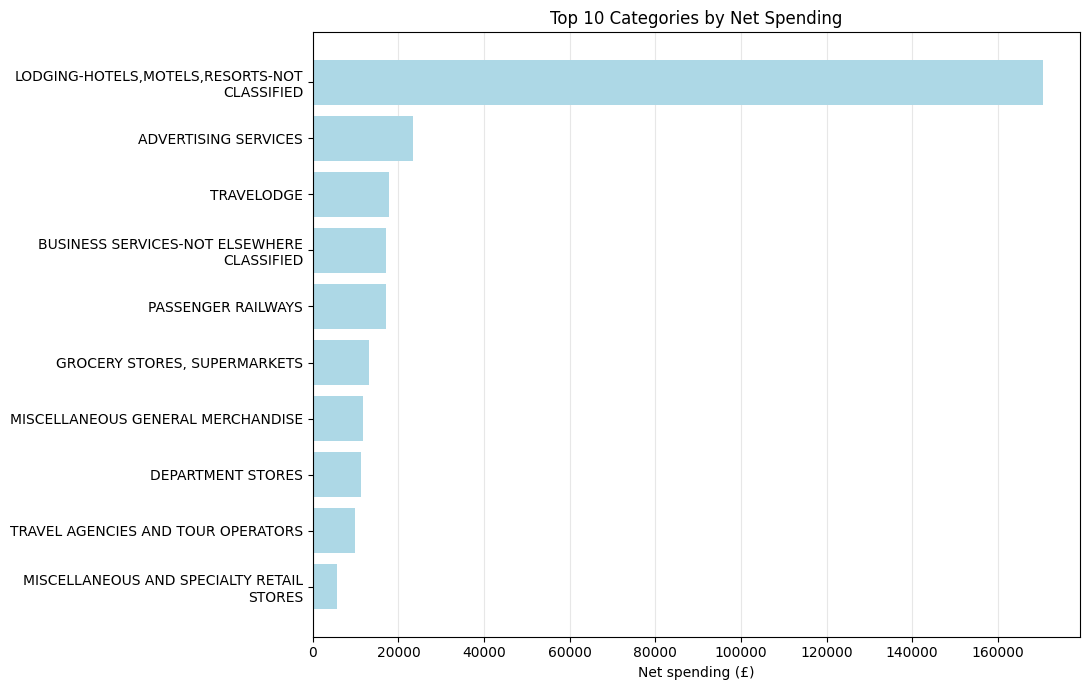

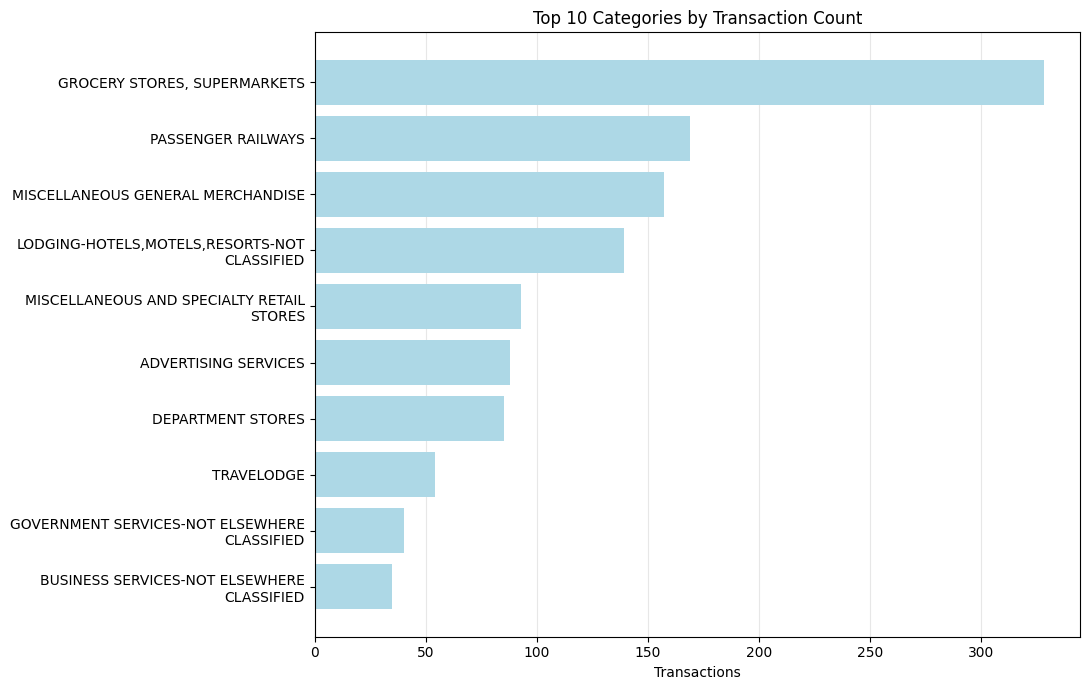

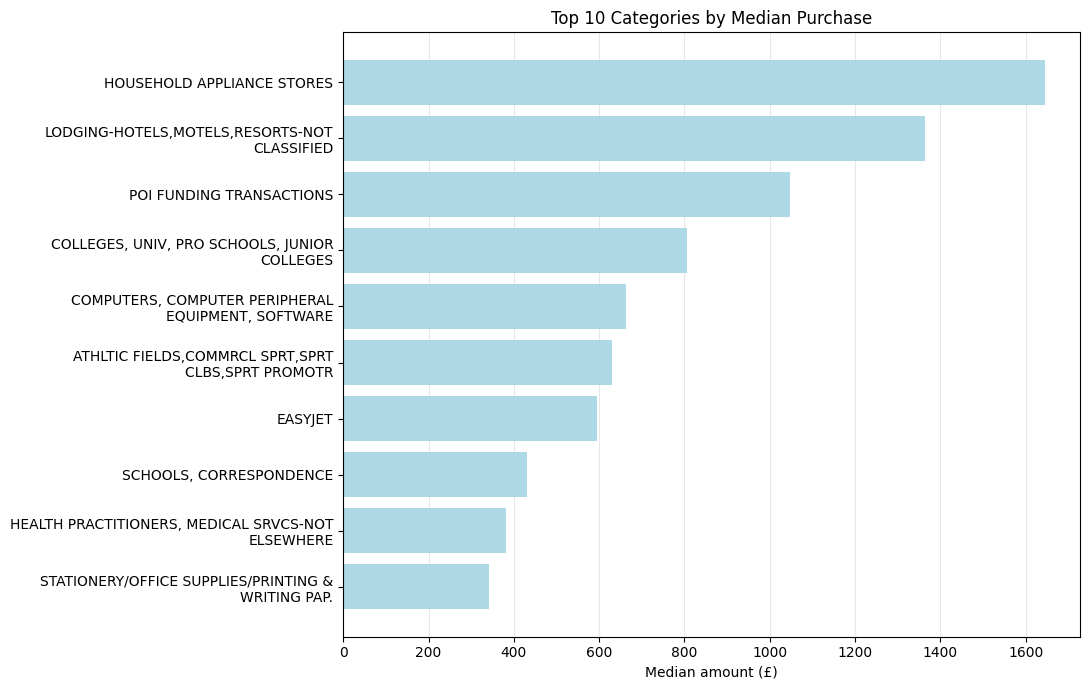

In [ ]:
import textwrap

category_summary = (
    CombinedDF.groupby("Procurement (Merchant) Category", dropna=False)
    ["Gross Amount (£)"]
    .agg(
        transaction_count="count",
        total_spending="sum",
        median_purchase="median",
        largest_purchase="max"
    )
    .sort_values("total_spending", ascending=False)
)

print(category_summary)

# Create three category comparisons.
charts = [
    ("total_spending", "Top 10 Categories by Net Spending", "Net spending (£)"),
    ("transaction_count", "Top 10 Categories by Transaction Count", "Transactions"),
    ("median_purchase", "Top 10 Categories by Median Purchase", "Median amount (£)")
]

for metric, title, xlabel in charts:
    top10 = category_summary.nlargest(10, metric).sort_values(metric)

    labels = [
        textwrap.fill(str(category), width=40)
        if pd.notna(category) else "Missing category"
        for category in top10.index
    ]

    fig, ax = plt.subplots(figsize=(11, 7))

    ax.barh(labels, top10[metric], color="lightblue")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.xaxis.grid(True, alpha=0.3)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

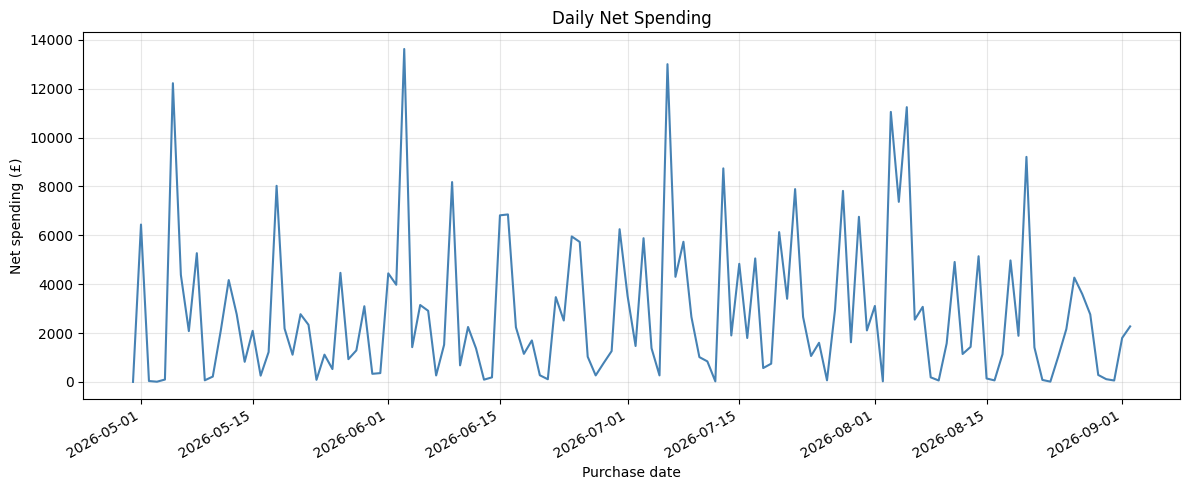

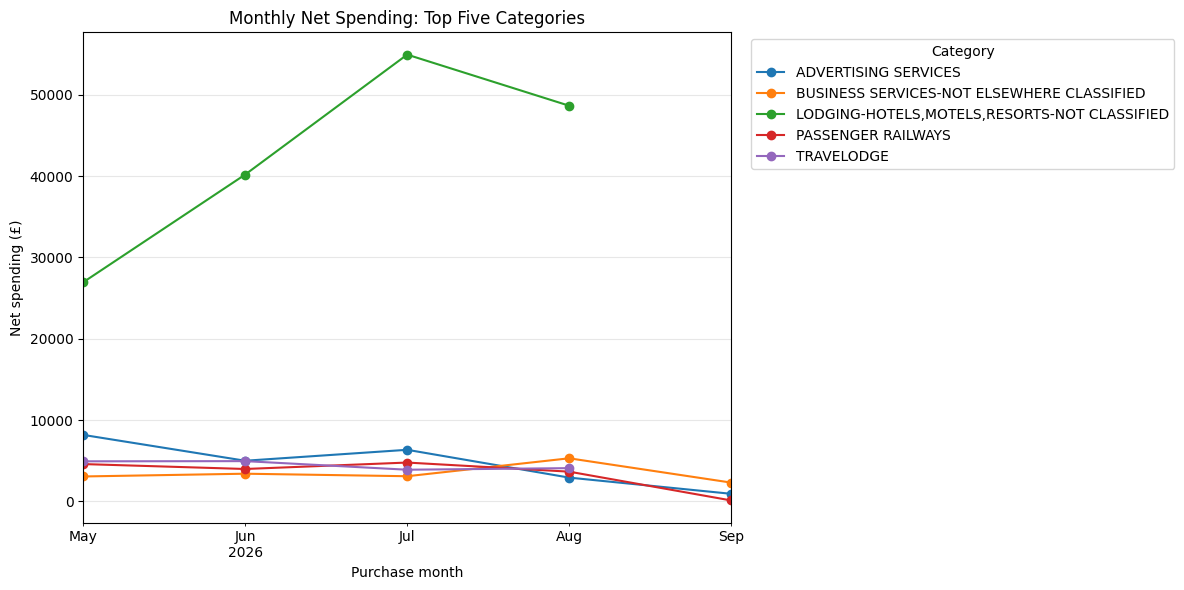

In [ ]:
dated = CombinedDF.dropna(subset=["Purchase Date"]).copy()

# 1. Daily net spending
daily_spending = (
    dated.set_index("Purchase Date")["Gross Amount (£)"]
    .resample("D")
    .sum(min_count=1)
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(daily_spending.index, daily_spending, color="steelblue")
ax.set_title("Daily Net Spending")
ax.set_xlabel("Purchase date")
ax.set_ylabel("Net spending (£)")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


# 2. Monthly spending for the top five categories
category_col = "Procurement (Merchant) Category"

top_categories = (
    dated.groupby(category_col)["Gross Amount (£)"]
    .sum()
    .nlargest(5)
    .index
)

monthly_categories = (
    dated[dated[category_col].isin(top_categories)]
    .groupby([
        dated["Purchase Date"].dt.to_period("M"),
        category_col
    ])["Gross Amount (£)"]
    .sum(min_count=1)
    .unstack()
    .sort_index()
)

# Use timestamps for plotting.
monthly_categories.index = monthly_categories.index.to_timestamp()

ax = monthly_categories.plot(
    figsize=(12, 6),
    marker="o"
)

ax.set_title("Monthly Net Spending: Top Five Categories")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Net spending (£)")
ax.grid(alpha=0.3)
ax.legend(title="Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#Outliers with IQR
To calculate the outliers using IQR I am using the below calculations

IQR = 75% - 25%

IQR = Q3 - Q1

Lower Bound Outlier

25th percentile - (1.5 * IQR)

Upper Bound Outlier

75th percentile + (1.5 *IQR)


In [ ]:
import pandas as pd

category_col = "Procurement (Merchant) Category"
amount_col = "Gross Amount (£)"

# Work on a copy and keep all original transactions.
IQRDF = CombinedDF.copy()

# Use positive purchases with known categories to calculate thresholds.
purchases = IQRDF.loc[
    IQRDF[amount_col].gt(0) & IQRDF[category_col].notna()
]

# Calculate each category's quartiles.
category_iqr = (
    purchases.groupby(category_col)[amount_col]
    .agg(
        purchase_count="count",
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75)
    )
)

category_iqr["IQR"] = category_iqr["Q3"] - category_iqr["Q1"]
category_iqr["upper_threshold"] = (
    category_iqr["Q3"] + 1.5 * category_iqr["IQR"]
)

category_iqr["eligible"] = (
    category_iqr["purchase_count"].ge(10)
    & category_iqr["IQR"].gt(0)
)

# Attach the category thresholds to each transaction.
IQRDF = IQRDF.join(category_iqr, on=category_col)

# Missing means the transaction was not assessed.
IQRDF["iqr_outlier"] = pd.Series(
    pd.NA, index=IQRDF.index, dtype="boolean"
)

assessed = (
    IQRDF[amount_col].gt(0)
    & IQRDF["eligible"].eq(True)
)

IQRDF.loc[assessed, "iqr_outlier"] = (
    IQRDF.loc[assessed, amount_col]
    > IQRDF.loc[assessed, "upper_threshold"]
)

# Show flagged purchases, largest first.
outliers = (
    IQRDF.loc[IQRDF["iqr_outlier"].fillna(False)]
    .sort_values(amount_col, ascending=False)
)

print("Purchases assessed:", int(assessed.sum()))
print("Outliers flagged:", len(outliers))

if assessed.sum() > 0:
    print(f"Outlier rate: {len(outliers) / assessed.sum():.1%}")

print(outliers[
    [
        category_col,
        "Supplier (Beneficiary)",
        "Purchase Date",
        amount_col,
        "upper_threshold"
    ]
].head(20))

Purchases assessed: 1423
Outliers flagged: 91
Outlier rate: 6.4%
                        Procurement (Merchant) Category  \
1600                 TRAVEL AGENCIES AND TOUR OPERATORS   
1490       LODGING-HOTELS,MOTELS,RESORTS-NOT CLASSIFIED   
1092         BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED   
34           BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED   
1503         BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED   
1492         BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED   
458          BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED   
1676         BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED   
748   EQUIP, FURNITURE, HOME FURNSHNGS STRS (EXCPT A...   
366                   MISCELLANEOUS GENERAL MERCHANDISE   
1139                  MISCELLANEOUS GENERAL MERCHANDISE   
310                                          TRAVELODGE   
1559                 TRAVEL AGENCIES AND TOUR OPERATORS   
1575                                         TRAVELODGE   
957                            COMPUTER SOFTWARE S

#Outliers with Z-Score
Calculations of how I found the outliers via Z-Score

Z-Score = (Data Point - Mean)/Standard Deviation

If Z-Score is above 3 it is marked as an outlier.

In [ ]:
import pandas as pd

category_col = "Procurement (Merchant) Category"
amount_col = "Gross Amount (£)"

ZScoreDF = CombinedDF.copy()

# Use positive purchases with known categories.
purchases = ZScoreDF.loc[
    ZScoreDF[amount_col].gt(0)
    & ZScoreDF[category_col].notna()
]

# Calculate category statistics.
category_stats = (
    purchases.groupby(category_col)[amount_col]
    .agg(
        purchase_count="count",
        category_mean="mean",
        category_std="std"
    )
)

# Starting rule: at least 10 purchases and nonzero standard deviation.
category_stats["eligible"] = (
    category_stats["purchase_count"].ge(10)
    & category_stats["category_std"].gt(0)
)

ZScoreDF = ZScoreDF.join(category_stats, on=category_col)

assessed = (
    ZScoreDF[amount_col].gt(0)
    & ZScoreDF["eligible"].eq(True)
)

ZScoreDF["z_score"] = float("nan")

ZScoreDF.loc[assessed, "z_score"] = (
    (
        ZScoreDF.loc[assessed, amount_col]
        - ZScoreDF.loc[assessed, "category_mean"]
    )
    / ZScoreDF.loc[assessed, "category_std"]
)

# Leave unassessed transactions as missing.
ZScoreDF["z_outlier"] = pd.Series(
    pd.NA, index=ZScoreDF.index, dtype="boolean"
)

ZScoreDF.loc[assessed, "z_outlier"] = (
    ZScoreDF.loc[assessed, "z_score"] > 3
)

z_outliers = (
    ZScoreDF.loc[ZScoreDF["z_outlier"].fillna(False)]
    .sort_values("z_score", ascending=False)
)

print("Purchases assessed:", int(assessed.sum()))
print("Outliers flagged:", len(z_outliers))

if assessed.sum() > 0:
    print(f"Outlier rate: {len(z_outliers) / assessed.sum():.1%}")

print(z_outliers[
    [
        category_col,
        "Supplier (Beneficiary)",
        "Purchase Date",
        amount_col,
        "category_mean",
        "z_score"
    ]
].head(20))

Purchases assessed: 1423
Outliers flagged: 20
Outlier rate: 1.4%
                        Procurement (Merchant) Category  \
466                        GROCERY STORES, SUPERMARKETS   
366                   MISCELLANEOUS GENERAL MERCHANDISE   
1139                  MISCELLANEOUS GENERAL MERCHANDISE   
1427                                 PASSENGER RAILWAYS   
80                                   PASSENGER RAILWAYS   
914           MISCELLANEOUS AND SPECIALTY RETAIL STORES   
9                   AUTOMOBILE PARKING LOTS AND GARAGES   
1078                                 PASSENGER RAILWAYS   
386           MISCELLANEOUS AND SPECIALTY RETAIL STORES   
1460                              FAST FOOD RESTAURANTS   
432        GOVERNMENT SERVICES-NOT ELSEWHERE CLASSIFIED   
1340                         EATING PLACES, RESTAURANTS   
1490       LODGING-HOTELS,MOTELS,RESORTS-NOT CLASSIFIED   
851                   MISCELLANEOUS GENERAL MERCHANDISE   
1600                 TRAVEL AGENCIES AND TOUR OPER

#Outliers with Isolation Forest
Isolation Forest detects outliers by measuring how easily a transaction can be separated from other transactions.

The model builds random trees that repeatedly divide the data. Transactions requiring fewer divisions to isolate receive stronger anomaly scores because their characteristics differ from most other transactions. The analysis used 300 trees and a contamination setting of 5%, selecting approximately 5% of eligible purchases for review.

The # of trees can be configured and also the % cutoff.

In [ ]:
amount_col = "Gross Amount (£)"
category_col = "Procurement (Merchant) Category"
supplier_col = "Supplier (Beneficiary)"
date_col = "Purchase Date"

# Keep positive purchases with the fields needed for this model.
IsolationDF = CombinedDF.loc[
    CombinedDF[amount_col].gt(0)
].dropna(
    subset=[amount_col, category_col, supplier_col, date_col]
).copy().reset_index(drop=True)

# Compare amounts with typical spending in their category.
category_median = (
    IsolationDF.groupby(category_col)[amount_col]
    .transform("median")
)

supplier_count = (
    IsolationDF.groupby(supplier_col)[amount_col]
    .transform("size")
)

# Normalize dates so purchases on the same day are grouped together.
IsolationDF["purchase_day"] = IsolationDF[date_col].dt.normalize()

supplier_daily_count = (
    IsolationDF.groupby([supplier_col, "purchase_day"])[amount_col]
    .transform("size")
)

# Log transforms reduce the influence of very large values.
features = pd.DataFrame({
    "log_amount": np.log1p(IsolationDF[amount_col]),
    "log_category_ratio": np.log1p(
        IsolationDF[amount_col] / category_median
    ),
    "log_supplier_count": np.log1p(supplier_count),
    "log_supplier_daily_count": np.log1p(supplier_daily_count)
})

model = IsolationForest(
    n_estimators=300,
    contamination=0.05,
    random_state=42
)

model.fit(features)

IsolationForest(contamination=0.05, n_estimators=300, random_state=42)

In [ ]:
# Predictions: -1 = outlier, 1 = other transaction.
IsolationDF["isolation_outlier"] = model.predict(features) == -1

# Reverse the score so higher values mean more unusual.
# This is an anomaly score, not a fraud probability.
IsolationDF["anomaly_score"] = -model.score_samples(features)

IsolationDF["category_amount_ratio"] = (
    IsolationDF[amount_col] / category_median
)

IsolationDF["supplier_transaction_count"] = supplier_count
IsolationDF["supplier_daily_count"] = supplier_daily_count

isolation_outliers = (
    IsolationDF.loc[IsolationDF["isolation_outlier"]]
    .sort_values("anomaly_score", ascending=False)
)

print("Transactions assessed:", len(IsolationDF))
print("Transactions excluded:", len(CombinedDF) - len(IsolationDF))
print("Outliers flagged:", len(isolation_outliers))
print(
    f"Outlier rate: "
    f"{IsolationDF['isolation_outlier'].mean():.1%}"
)

display(isolation_outliers[
    [
        supplier_col,
        category_col,
        date_col,
        amount_col,
        "category_amount_ratio",
        "supplier_transaction_count",
        "supplier_daily_count",
        "anomaly_score"
    ]
].head(20))

Transactions assessed: 1667
Transactions excluded: 45
Outliers flagged: 84
Outlier rate: 5.0%


,Supplier (Beneficiary),Procurement (Merchant) Category,Purchase Date,Gross Amount (£),category_amount_ratio,supplier_transaction_count,supplier_daily_count,anomaly_score
77,TRAINLINE,PASSENGER RAILWAYS,2026-05-18,943.66,10.997087,144,9,0.706819
1421,PIZZA HUT,FAST FOOD RESTAURANTS,2026-07-31,700.00,43.750000,2,2,0.696508
1066,AWS EMEA,BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED,2026-07-13,2601.56,33.415452,6,1,0.691506
448,AWS EMEA,BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED,2026-06-06,2005.00,25.753002,6,2,0.691408
32,AWS EMEA,BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED,2026-05-01,2529.91,32.495151,6,1,0.689710
537,JSA PRINT,MISCELLANEOUS PUBLISHING AND PRINTING,2026-06-16,1668.48,62.454801,1,1,0.688183
1462,AWS EMEA,BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED,2026-08-01,2446.21,31.420076,6,1,0.687950
1451,AWS EMEA,BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED,2026-09-02,2245.92,28.847473,6,1,0.681114
357,AMAZON UK N30YM34O4,MISCELLANEOUS GENERAL MERCHANDISE,2026-06-01,1500.00,42.052145,1,1,0.678903
1558,HOTEL AT BOOKING.COM,TRAVEL AGENCIES AND TOUR OPERATORS,2026-08-20,3942.80,20.577751,4,1,0.677054


#Outleirs with Local Outlier Factor (LOF)
Local Outlier Factor (LOF) detects transactions that are more isolated than their nearby peers.

The model compared the local density of each transaction with that of its 20 nearest neighbors. Transactions in substantially less dense areas than their neighbors received higher anomaly scores. The analysis used standardized features representing purchase amounts and supplier activity, with a contamination setting of 5% to select approximately 5% of eligible transactions for review.

Nearest neighbors and conamination % can be configured.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor

# LOF uses distances, so scale the features first.
scaled_features = StandardScaler().fit_transform(features)

lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05
)

# fit_predict: -1 = outlier, 1 = not flagged.
lof_predictions = lof_model.fit_predict(scaled_features)

LOFDF = IsolationDF.copy()

LOFDF["lof_outlier"] = lof_predictions == -1

# Higher scores mean more unusual.
# These scores are not fraud probabilities.
LOFDF["lof_score"] = -lof_model.negative_outlier_factor_

lof_outliers = (
    LOFDF.loc[LOFDF["lof_outlier"]]
    .sort_values("lof_score", ascending=False)
)

print("Transactions assessed:", len(LOFDF))
print("LOF outliers:", len(lof_outliers))
print(f"Outlier rate: {LOFDF['lof_outlier'].mean():.1%}")

display(lof_outliers[
    [
        supplier_col,
        category_col,
        date_col,
        amount_col,
        "category_amount_ratio",
        "supplier_transaction_count",
        "supplier_daily_count",
        "lof_score",
        "isolation_outlier",
        "lof_outlier"
    ]
].head(20))

Transactions assessed: 1667
LOF outliers: 84
Outlier rate: 5.0%


/usr/local/lib/python3.13/dist-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


,Supplier (Beneficiary),Procurement (Merchant) Category,Purchase Date,Gross Amount (£),category_amount_ratio,supplier_transaction_count,supplier_daily_count,lof_score,isolation_outlier,lof_outlier
577,MORRISONS CHEADLE - 12,"GROCERY STORES, SUPERMARKETS",2026-06-05,3.10,0.106183,68,1,5.638755e+09,False,True
1641,BKG HOTEL AT BOOKING.C,TRAVEL AGENCIES AND TOUR OPERATORS,2026-08-21,469.52,2.450458,14,1,4.754588e+09,False,True
1435,TRAVELODG TRAVELODGE G,TRAVELODGE,2026-08-28,907.65,3.184290,54,1,4.530295e+09,False,True
1534,TRAVELODG TRAVELODGE G,TRAVELODGE,2026-08-18,1049.43,3.681694,54,1,4.288712e+09,False,True
244,TRAVELODG TRAVELODGE G,TRAVELODGE,2026-05-12,674.14,2.365072,54,1,4.150752e+09,False,True
699,BKG HOTEL AT BOOKING.C,TRAVEL AGENCIES AND TOUR OPERATORS,2026-07-01,735.00,3.836017,14,1,4.086202e+09,False,True
1518,BKG HOTEL AT BOOKING.C,TRAVEL AGENCIES AND TOUR OPERATORS,2026-08-05,1152.20,6.013413,14,1,3.714175e+09,False,True
1507,BKG HOTEL AT BOOKING.C,TRAVEL AGENCIES AND TOUR OPERATORS,2026-08-17,665.02,3.470786,14,1,3.634804e+09,False,True
512,ARGOS,DEPARTMENT STORES,2026-06-05,371.95,3.837305,65,1,3.609169e+09,False,True
91,BKG HOTEL AT BOOKING.C,TRAVEL AGENCIES AND TOUR OPERATORS,2026-05-01,570.00,2.974870,14,1,3.559989e+09,False,True


#Comparing IQR, Z-Score, Isolation Forest, and LOF
IQR - Detected 91 Outliers

Z-Score - Detected 20 Outliers

Isolation Forest - Detected 84 Outliers

LOF - Detected 84 Outliers

Outliers do not automatically assume fraud. However they do flag them and help identify purchases that may be fraud. Further examination is required to determine fraud.

Z-Score had significantly less outliers flagged because the cutoff is much more strict. I would assume the outliers in Z-Score are more likely to be considered fraud because of the strict cutoffs.

The machine learning models used a 5% contamination setting, so their similar flag counts reflect the selected cutoff rather than equivalent performance.

In [ ]:
amount_col = "Gross Amount (£)"
category_col = "Procurement (Merchant) Category"
supplier_col = "Supplier (Beneficiary)"
date_col = "Purchase Date"

ComparisonDF = CombinedDF.copy().reset_index(drop=True)

check_cols = [amount_col, category_col, supplier_col, date_col]

# Verify and attach IQR and z-score results.
for method_df, flag in [
    (IQRDF, "iqr_outlier"),
    (ZScoreDF, "z_outlier")
]:
    pd.testing.assert_frame_equal(
        ComparisonDF[check_cols],
        method_df[check_cols].reset_index(drop=True),
        check_dtype=False
    )

    ComparisonDF[flag] = (
        method_df[flag].reset_index(drop=True).astype("boolean")
    )

# Isolation Forest and LOF assessed the same subset.
model_mask = (
    ComparisonDF[amount_col].gt(0)
    & ComparisonDF[check_cols].notna().all(axis=1)
)

# Verify and attach both model results.
for method_df, flag in [
    (IsolationDF, "isolation_outlier"),
    (LOFDF, "lof_outlier")
]:
    pd.testing.assert_frame_equal(
        ComparisonDF.loc[model_mask, check_cols].reset_index(drop=True),
        method_df[check_cols].reset_index(drop=True),
        check_dtype=False
    )

    ComparisonDF[flag] = pd.Series(
        pd.NA, index=ComparisonDF.index, dtype="boolean"
    )

    ComparisonDF.loc[model_mask, flag] = method_df[flag].to_numpy()

# Count assessed methods and positive flags.
flag_cols = [
    "iqr_outlier",
    "z_outlier",
    "isolation_outlier",
    "lof_outlier"
]

ComparisonDF["methods_assessed"] = (
    ComparisonDF[flag_cols].notna().sum(axis=1)
)

ComparisonDF["methods_flagged"] = (
    ComparisonDF[flag_cols].fillna(False).astype(int).sum(axis=1)
)

In [ ]:
flag_cols = [
    "iqr_outlier",
    "z_outlier",
    "isolation_outlier",
    "lof_outlier"
]

summary = pd.DataFrame({
    "assessed": ComparisonDF[flag_cols].notna().sum(),
    "outliers": ComparisonDF[flag_cols].fillna(False).sum()
})

summary["outlier_rate_pct"] = (
    summary["outliers"]
    / summary["assessed"].replace(0, float("nan"))
    * 100
).round(2)

display(summary)

,assessed,outliers,outlier_rate_pct
iqr_outlier,1423,91,6.39
z_outlier,1423,20,1.41
isolation_outlier,1667,84,5.04
lof_outlier,1667,84,5.04


#Further analysis of what was flagged

To determine which transactions are more likely to be fraud we can do more further analysis. For example, if a transaction is flagged by all 4 methods, it is more likely to be a fraud transaction. Same applies for 3 out of 4 flags; however, to a lesser extent.

In [ ]:
# Keep transactions assessed by all four methods.
common = ComparisonDF.loc[
    ComparisonDF["methods_assessed"].eq(4)
].copy()

overlap = (
    common.groupby(flag_cols)
    .size()
    .reset_index(name="transaction_count")
    .sort_values("transaction_count", ascending=False)
)

print("Transactions assessed by all four:", len(common))
display(overlap)

Transactions assessed by all four: 1423


,iqr_outlier,z_outlier,isolation_outlier,lof_outlier,transaction_count
0,False,False,False,False,1233
2,False,False,True,False,49
4,True,False,False,False,48
1,False,False,False,True,47
6,True,False,True,False,13
5,True,False,False,True,10
9,True,True,True,False,10
7,True,True,False,False,6
3,False,False,True,True,3
8,True,True,False,True,2


In [ ]:
category_stats = (
    ComparisonDF.loc[ComparisonDF[amount_col].gt(0)]
    .groupby(category_col)[amount_col]
    .agg(
        category_median="median",
        category_average="mean"
    )
)

review_list = (
    ComparisonDF.loc[ComparisonDF["methods_flagged"].gt(0)]
    .join(category_stats, on=category_col)
    .sort_values(
        ["methods_flagged", amount_col],
        ascending=[False, False]
    )
)

display(review_list[
    [
        supplier_col,
        category_col,
        date_col,
        amount_col,
        "category_median",
        "category_average",
        *flag_cols,
        "methods_assessed",
        "methods_flagged"
    ]
].head(30))

,Supplier (Beneficiary),Procurement (Merchant) Category,Purchase Date,Gross Amount (£),category_median,category_average,iqr_outlier,z_outlier,isolation_outlier,lof_outlier,methods_assessed,methods_flagged
80,TRAINLINE,PASSENGER RAILWAYS,2026-05-18,943.66,85.810,114.736875,True,True,True,True,4,4
1078,TRAINLINE,PASSENGER RAILWAYS,2026-07-21,784.40,85.810,114.736875,True,True,True,True,4,4
1600,HOTEL AT BOOKING.COM,TRAVEL AGENCIES AND TOUR OPERATORS,2026-08-20,3942.80,191.605,492.605000,True,True,True,False,4,3
1490,PERFECT BOOKING,"LODGING-HOTELS,MOTELS,RESORTS-NOT CLASSIFIED",2026-08-05,3530.57,1364.160,1237.362101,True,True,False,True,4,3
366,AMAZON UK N30YM34O4,MISCELLANEOUS GENERAL MERCHANDISE,2026-06-01,1500.00,35.670,81.775850,True,True,True,False,4,3
1139,AMAZON 0F3RL5UG5,MISCELLANEOUS GENERAL MERCHANDISE,2026-07-04,1360.58,35.670,81.775850,True,True,True,False,4,3
1427,TRAINLINE,PASSENGER RAILWAYS,2026-08-03,943.75,85.810,114.736875,True,True,True,False,4,3
432,OFSTED INTERNET,GOVERNMENT SERVICES-NOT ELSEWHERE CLASSIFIED,2026-06-25,910.00,40.000,122.146053,True,True,True,False,4,3
851,AMAZON UK NR1DD8X64,MISCELLANEOUS GENERAL MERCHANDISE,2026-06-15,805.90,35.670,81.775850,True,True,True,False,4,3
466,ASDA GEORGE COM LEEDS,"GROCERY STORES, SUPERMARKETS",2026-06-22,747.28,29.195,39.932043,True,True,True,False,4,3


#Visualization of the data and it's outliers



['MISCELLANEOUS GENERAL MERCHANDISE' 'OFFICE AND COMMERCIAL FURNITURE'
 'DEPARTMENT STORES' 'AUTOMOBILE PARKING LOTS AND GARAGES'
 'SCHOOLS & EDUCATIONAL SVC-NOT ELSEWHERE CLASSIFIED'
 'GROCERY STORES, SUPERMARKETS'
 'GOVERNMENT SERVICES-NOT ELSEWHERE CLASSIFIED'
 'BUSINESS SERVICES-NOT ELSEWHERE CLASSIFIED'
 'COMPUTER NETWORK/INFORMATION SERVICES'
 'COMP PROGRAMING,DATA PRCSNG,INTGRTD SYS DSGN SRVS'
 'COMPUTER SOFTWARE STORES' 'MISCELLANEOUS AND SPECIALTY RETAIL STORES'
 'DIRECT MARKETING-CONTINUITY/SUBSCRIPTION MERCHANTS'
 'SERVICE STATIONS WITH OR WITHOUT ANCILLARY SERVICE'
 'CONSULTING, MANAGEMENT, AND PUBLIC RELATIONS SVCS'
 'DIRECT MARKETING-OTHER DIRECT MARKETERS/NOT ELSEW.'
 'LAWN AND GARDEN SUPPLY STORES'
 'LODGING-HOTELS,MOTELS,RESORTS-NOT CLASSIFIED'
 'TRAVEL AGENCIES AND TOUR OPERATORS' 'ADVERTISING SERVICES'
 'COMMERCIAL ART, GRAPHICS, PHOTOGRAPHY'
 'DIGITAL GOODS SOFTWARE APPLICATIONS' 'DIGITAL GOODS AUDIOVISUAL MEDIA'
 'PASSENGER RAILWAYS' 'COMPUTERS, COMPUTER PERIPHERAL

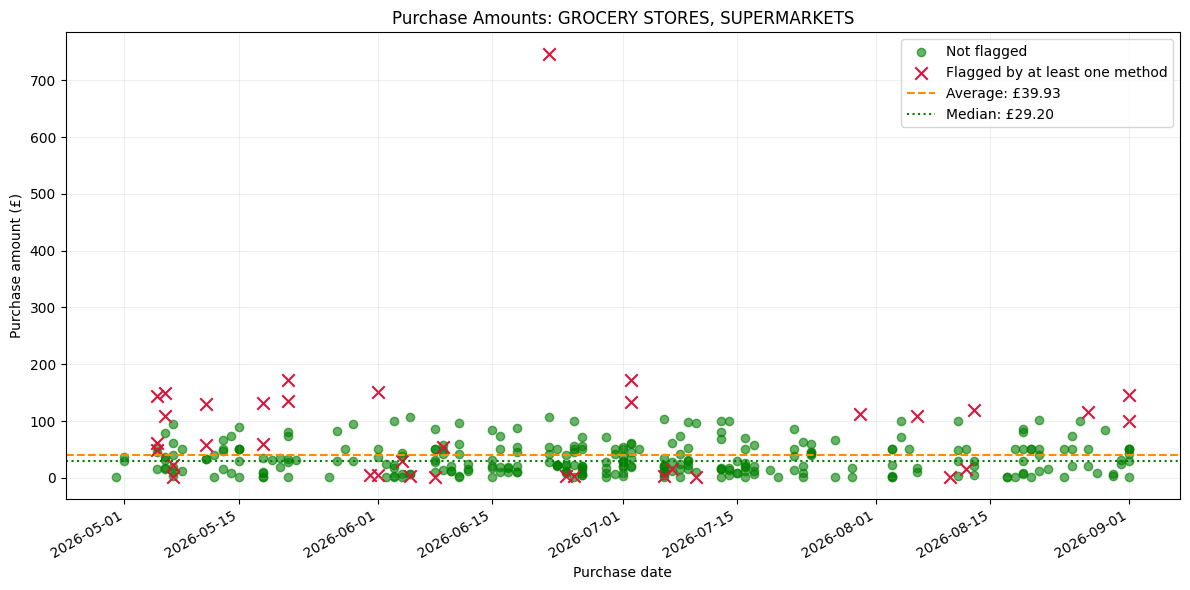

In [ ]:
# See available categories.
print(ComparisonDF[category_col].dropna().unique())
# Replace this with any category listed below, "GROCERY STORES, SUPERMARKETS" as placeholder
selected_category = "GROCERY STORES, SUPERMARKETS"

# Use all positive purchases in the category.
plot_df = (
    ComparisonDF.loc[
        ComparisonDF[category_col].eq(selected_category)
        & ComparisonDF[amount_col].gt(0)
    ]
    .sort_values(date_col)
    .copy()
)

if plot_df.empty:
    print("No positive purchases found for this category.")
else:
    average = plot_df[amount_col].mean()
    median = plot_df[amount_col].median()

    flagged = plot_df["methods_flagged"].gt(0)

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.scatter(
        plot_df.loc[~flagged, date_col],
        plot_df.loc[~flagged, amount_col],
        color="green",
        alpha=0.6,
        label="Not flagged"
    )

    ax.scatter(
        plot_df.loc[flagged, date_col],
        plot_df.loc[flagged, amount_col],
        color="crimson",
        marker="x",
        s=80,
        label="Flagged by at least one method"
    )

    ax.axhline(
        average,
        color="darkorange",
        linestyle="--",
        label=f"Average: £{average:,.2f}"
    )

    ax.axhline(
        median,
        color="green",
        linestyle=":",
        label=f"Median: £{median:,.2f}"
    )

    ax.set_title(f"Purchase Amounts: {selected_category}")
    ax.set_xlabel("Purchase date")
    ax.set_ylabel("Purchase amount (£)")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.autofmt_xdate()

    plt.tight_layout()
    plt.show()

#Conclusion, Limitation, Next Steps
The dataset lacked several important information such as cardholder identifiers, receipts, approval records, and verified fraud outcomes. Supplier categories may also affect frequency-based features. All methods use the full dataset in retrospect, so the results do not establish performance on future transactions. Flagged purchases should be reviewed against business cases and a sample of unflagged purchases should also be examined for potentially missed issues.